In [1]:
import pandas as pd

df = pd.read_csv("../data/city_day.csv")
df.head()



,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [4]:
# Check the first few rows
df.head()


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [5]:
# Check the structure of your dataset (columns, data types, etc.)
df.info()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [5]:
# Get a quick statistical summary of numeric columns
df.describe()


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [6]:
# Drop rows where AQI is missing
df = df.dropna(subset=['AQI'])

# Optional: Drop columns with too many missing values (like Xylene)
df = df.drop(columns=['Xylene'])

# Fill remaining missing values with column mean
df = df.fillna(df.mean(numeric_only=True))

# Check if it worked
df.isnull().sum()


City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
AQI           0
AQI_Bucket    0
dtype: int64

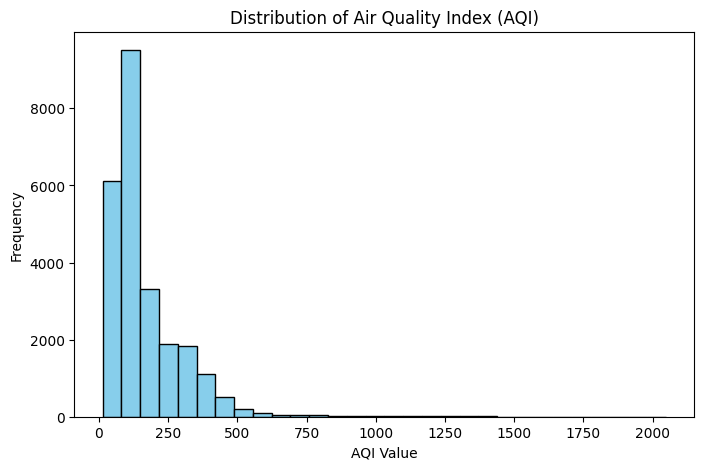

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["AQI"], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribution of Air Quality Index (AQI)")
plt.xlabel("AQI Value")
plt.ylabel("Frequency")
plt.show()


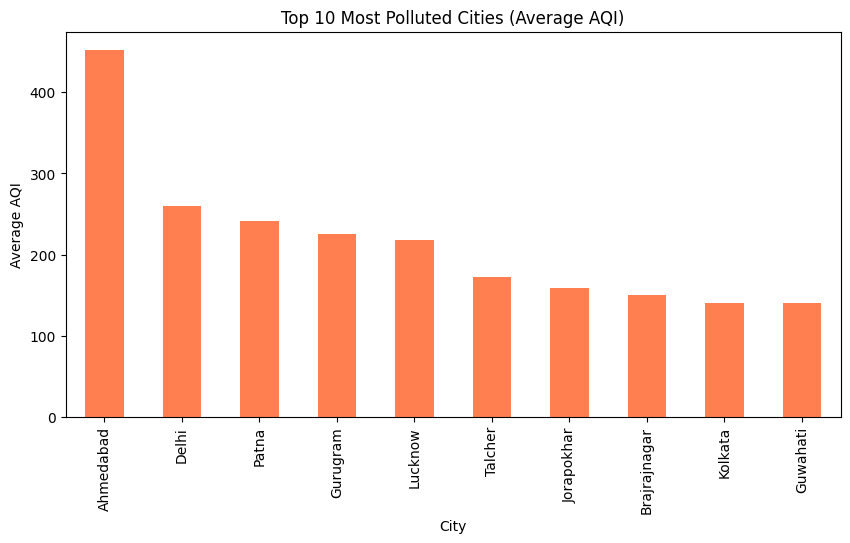

In [8]:
avg_aqi_city = df.groupby("City")["AQI"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
avg_aqi_city.plot(kind='bar', color='coral')
plt.title("Top 10 Most Polluted Cities (Average AQI)")
plt.ylabel("Average AQI")
plt.show()


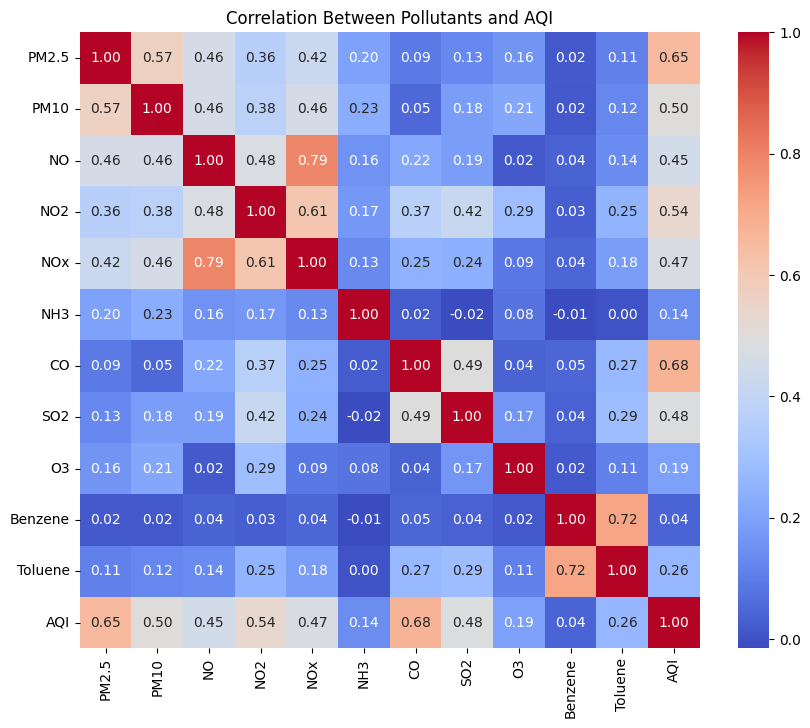

In [9]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Pollutants and AQI")
plt.show()


In [12]:
!pip install scikit-learn


   ---------------------------------------- 0.0/8.7 MB ? eta -:--:--
   --------------- ------------------------ 3.4/8.7 MB 26.7 MB/s eta 0:00:01
   ---------------------------------------- 8.7/8.7 MB 24.2 MB/s  0:00:00
   ---------------------------------------- 0.0/38.5 MB ? eta -:--:--
   ------- -------------------------------- 6.8/38.5 MB 31.6 MB/s eta 0:00:02
   ------------ --------------------------- 11.8/38.5 MB 27.3 MB/s eta 0:00:01
   ------------------ --------------------- 17.8/38.5 MB 27.7 MB/s eta 0:00:01
   ----------------------- ---------------- 22.8/38.5 MB 26.6 MB/s eta 0:00:01
   ----------------------------- ---------- 28.6/38.5 MB 26.9 MB/s eta 0:00:01
   ----------------------------------- ---- 34.3/38.5 MB 27.0 MB/s eta 0:00:01
   ---------------------------------------  38.3/38.5 MB 27.6 MB/s eta 0:00:01
   ---------------------------------------- 38.5/38.5 MB 25.7 MB/s  0:00:01

   ---------- ----------------------------- 1/4 [scipy]
   ---------- -----------


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


In [14]:
# Select feature columns (all numeric pollutant columns)
features = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
X = df[features]
y = df['AQI']

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [15]:
model = LinearRegression()
model.fit(X_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R² Score:", r2)


Mean Absolute Error: 31.213353136655012
R² Score: 0.809182256143111


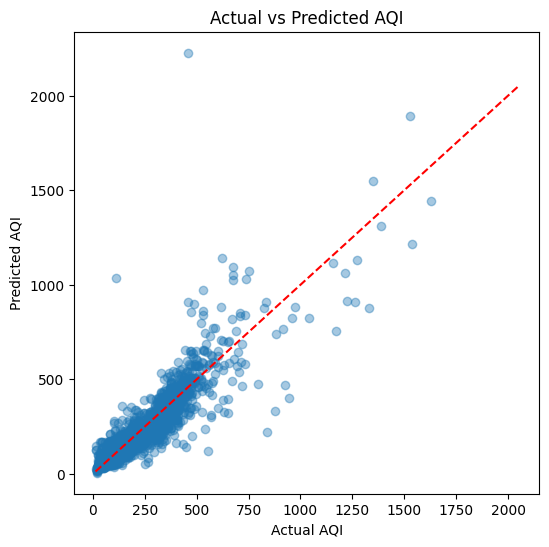

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(y_test,y_pred,alpha=0.4)
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--', color='red')
plt.xlabel('Actual AQI'); plt.ylabel('Predicted AQI'); plt.title('Actual vs Predicted AQI')
plt.show()


<Axes: >

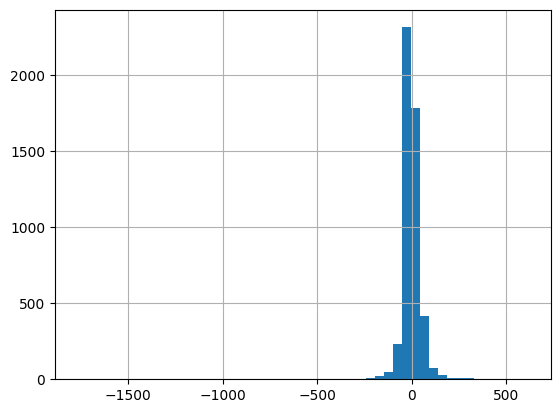

In [20]:
residuals = y_test - y_pred
residuals.hist(bins=50)


In [22]:
import pandas as pd

# define the list of features again (just in case your notebook kernel restarted)
features = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene']

# extract and store coefficients from your trained linear regression model
coeffs = pd.Series(model.coef_, index=features).sort_values(ascending=False)


In [ ]:
import os
os.makedirs("visuals", exist_ok=True)


In [27]:
plt.savefig("visuals/feature_importance.png")


<Figure size 640x480 with 0 Axes>

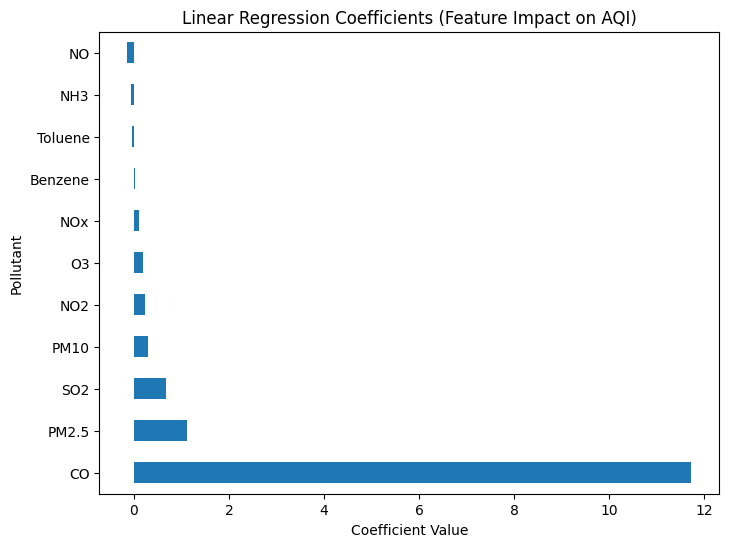

In [28]:
import matplotlib.pyplot as plt

coeffs.plot(kind='barh', figsize=(8,6))
plt.title('Linear Regression Coefficients (Feature Impact on AQI)')
plt.xlabel('Coefficient Value')
plt.ylabel('Pollutant')
plt.show()


In [32]:
os.makedirs("models", exist_ok=True)
import joblib
joblib.dump(model, "models/aqi_linear_model.pkl")


['models/aqi_linear_model.pkl']